# Maths into AI student course
## Linear regression

## Predicting CO<sub>2</sub> emissions - modelling with linear regression
The CO<sub>2</sub> emissions from transport account for approximately a quarter of all CO2 emissions from energy production and of this about half is from cars and buses (https://ourworldindata.org/co2-emissions-from-transport).

The amount of CO<sub>2</sub> produced differs for different cars. In this notebook you will explore which features of cars can be used to build a linear model to predict the CO2 emissions.

## Importing libraries and data

In [1]:
import pandas as pd 
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
# import the data
cars_data = pd.read_csv('../input/aqalds/AQA-large-data-set.csv')

# check the data has imported
cars_data

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number
0,440,VAUXHALL,1,96,London,1,1598,2002,1970,190,0.219,0.026,NaN,0.037,0.430217
1,1465,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.797111
2,3434,VOLKSWAGEN,1,14,South West,2,1395,2016,1316,113,0.242,0.033,NaN,0.048,0.348442
3,1801,VAUXHALL,1,14,South West,4,1598,2016,1355,159,0.809,0.012,NaN,0.051,0.968447
4,2330,BMW,2,13,South West,5,1995,2016,1445,114,0.180,0.023,NaN,NaN,0.178227
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3822,2920,FORD,2,14,North West,5,1997,2016,1681,122,0.145,0.059,0.001,NaN,0.946550
3823,1800,FORD,2,96,London,2,1997,2016,1833,134,0.305,0.054,NaN,NaN,0.538774
3824,3498,FORD,1,14,South West,1,999,2016,1333,108,0.447,0.030,0.002,0.076,0.736612
3825,2802,VAUXHALL,1,14,North West,5,1364,2016,1409,149,0.699,0.008,NaN,0.044,0.748846


The data set contains information about cars including make, engine size, mass, year registered and emissions. The data features five different makes of car from two years (2002 and 2016).

There are 3,827 individual records, each representing a single car.

Features:
* **Make**: *Only 5 makes of car are included*
* **PropulsionTypeId**: *A code for the type of fuel used*
 	*1 =  Petrol, 2 = Diesel, 3 = Electric, 7 = Gas/Petrol, 8 = Electric/Petrol*
* **BodyTypeId**: *A code for the body type*
 	*1 =  2-door saloon, 2 = 4-door saloon, 3 = Saloon, 4 = Convertible, 5 = Coupe, 6 = Estate, 13 = 3-Door Hatchback, 14 = 5-Door Hatchback, 96 = Multi-Purpose Vehicle*
* **GovRegion**: *English region of the current registered keeper*
* **KeeperTitleId**: *A code for the title of the registered keeper*
 	*1 = Male, 2 = Female, 3 = (Not used), 4  = Unknown (Rev, Dr etc.), 5 = Company*
* **EngineSize**: *Engine capacity (cm³)*
* **YearRegistered**: *The year in which the vehicle was first registered*
* **Mass**: *Mass of vehicle, including 75 kg for the mass of an average driver (kg)*
* **CO2**: *Carbon dioxide emissions from the vehicle (g/km)*
* **CO**: *Carbon monoxide emissions(g/km)*
* **NOX**: *Nitrogen oxide emissions (g/km)*
* **part**: *Particulate emissions (g/km)*
* **hc**: *Hydrocarbon emissions (g/km)*


In [3]:
# get the data types
cars_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3827 entries, 0 to 3826
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ReferenceNumber   3827 non-null   int64  
 1   Make              3827 non-null   object 
 2   PropulsionTypeId  3827 non-null   int64  
 3   BodyTypeId        3827 non-null   int64  
 4   GovRegion         3827 non-null   object 
 5   KeeperTitleId     3827 non-null   int64  
 6   EngineSize        3827 non-null   int64  
 7   YearRegistered    3827 non-null   int64  
 8   Mass              3827 non-null   int64  
 9   CO2               3827 non-null   int64  
 10  CO                3814 non-null   float64
 11  NOX               3753 non-null   float64
 12  part              722 non-null    float64
 13  hc                2405 non-null   float64
 14  Random number     3827 non-null   float64
dtypes: float64(5), int64(8), object(2)
memory usage: 448.6+ KB


# Preparing the data

## Adding text for a categorical feature
The data type for `PropulsionTypeId` is an integer. It will be useful to create a new feature with the relevant text values.

In [4]:
# the PropulsionTypeId field is overwritten with the values from the list using the replace command
# the replace list uses a colon to indicate what is to be replaced and a commas to separate the items
cars_data['PropulsionType'] = cars_data['PropulsionTypeId'].replace({1: 'Petrol',
                                                                     2: 'Diesel',
                                                                     3: 'Electric', 
                                                                     7: 'Gas/Petrol', 
                                                                     8: 'Electric/Petrol'})
# dsiplay to check
cars_data

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
0,440,VAUXHALL,1,96,London,1,1598,2002,1970,190,0.219,0.026,NaN,0.037,0.430217,Petrol
1,1465,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.797111,Petrol
2,3434,VOLKSWAGEN,1,14,South West,2,1395,2016,1316,113,0.242,0.033,NaN,0.048,0.348442,Petrol
3,1801,VAUXHALL,1,14,South West,4,1598,2016,1355,159,0.809,0.012,NaN,0.051,0.968447,Petrol
4,2330,BMW,2,13,South West,5,1995,2016,1445,114,0.180,0.023,NaN,NaN,0.178227,Diesel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3822,2920,FORD,2,14,North West,5,1997,2016,1681,122,0.145,0.059,0.001,NaN,0.946550,Diesel
3823,1800,FORD,2,96,London,2,1997,2016,1833,134,0.305,0.054,NaN,NaN,0.538774,Diesel
3824,3498,FORD,1,14,South West,1,999,2016,1333,108,0.447,0.030,0.002,0.076,0.736612,Petrol
3825,2802,VAUXHALL,1,14,North West,5,1364,2016,1409,149,0.699,0.008,NaN,0.044,0.748846,Petrol


## Removing zero entries
In this task you will be trying to find a model to preduct CO<sub>2</sub> emissions. You can start by exploring the CO<sub>2</sub> feature to check the values.

In [5]:
# use describe to check the CO2 feature
cars_data['CO2'].describe()

count    3827.000000
mean      137.628691
std        36.555543
min         0.000000
25%       114.000000
50%       129.000000
75%       158.000000
max       356.000000
Name: CO2, dtype: float64

The minimum of 0 is worth investigating further. You can display the rows where CO2 is 0.

In [6]:
# display rows where CO2 is 0
cars_data[cars_data['CO2']==0]

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
446,3645,BMW,3,14,South West,2,0,2016,1270,0,NaN,NaN,NaN,NaN,0.872725,Electric
2404,937,VOLKSWAGEN,1,14,London,1,1198,2002,1132,0,0.68,0.042,NaN,0.03,0.829275,Petrol


The electric car has a `CO2` value of 0. This can be removed so that we are only building a model for non-electric cars. 

A `CO2` value of 0 for a petrol car is unlikely. This can be removed too.

In [7]:
# Remove the zero rows by copying when it is not equal to 0
cars_data_clean=cars_data[cars_data['CO2']!=0].copy()

# check the data
cars_data_clean

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
0,440,VAUXHALL,1,96,London,1,1598,2002,1970,190,0.219,0.026,NaN,0.037,0.430217,Petrol
1,1465,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.797111,Petrol
2,3434,VOLKSWAGEN,1,14,South West,2,1395,2016,1316,113,0.242,0.033,NaN,0.048,0.348442,Petrol
3,1801,VAUXHALL,1,14,South West,4,1598,2016,1355,159,0.809,0.012,NaN,0.051,0.968447,Petrol
4,2330,BMW,2,13,South West,5,1995,2016,1445,114,0.180,0.023,NaN,NaN,0.178227,Diesel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3822,2920,FORD,2,14,North West,5,1997,2016,1681,122,0.145,0.059,0.001,NaN,0.946550,Diesel
3823,1800,FORD,2,96,London,2,1997,2016,1833,134,0.305,0.054,NaN,NaN,0.538774,Diesel
3824,3498,FORD,1,14,South West,1,999,2016,1333,108,0.447,0.030,0.002,0.076,0.736612,Petrol
3825,2802,VAUXHALL,1,14,North West,5,1364,2016,1409,149,0.699,0.008,NaN,0.044,0.748846,Petrol


You can check if there are any other rows where the EngineSize or Mass are 0.

In [8]:
# display rows where EngineSize OR Mass is 0
cars_data_clean[(cars_data_clean['EngineSize']==0) |(cars_data_clean['Mass']==0)]

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
45,588,BMW,1,3,London,1,2979,2002,0,230,0.447,NaN,NaN,NaN,0.408561,Petrol
70,871,TOYOTA,1,5,London,2,1794,2002,0,185,NaN,NaN,NaN,NaN,0.223595,Petrol
91,861,FORD,1,3,South West,1,1596,2002,0,165,0.518,NaN,NaN,NaN,0.641704,Petrol
98,1282,TOYOTA,1,14,South West,2,998,2002,0,137,0.430,NaN,NaN,NaN,0.562930,Petrol
201,1190,BMW,2,3,South West,1,2926,2002,0,178,0.327,NaN,NaN,NaN,0.578066,Diesel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3589,363,FORD,1,14,North West,1,1596,2002,0,165,0.518,0.059,NaN,NaN,0.271451,Petrol
3611,1270,FORD,2,14,South West,2,1753,2002,0,145,0.109,0.489,NaN,0.018,0.855653,Diesel
3697,833,VOLKSWAGEN,2,14,North West,2,1896,2002,0,140,0.081,NaN,NaN,NaN,0.257505,Diesel
3756,878,VOLKSWAGEN,2,3,London,1,1896,2002,0,138,0.073,NaN,NaN,NaN,0.838346,Diesel


There are a further 92 rows that have either EngineSize or Mass of 0. These can be removed from the data set.

In [9]:
# Removing these rows
cars_data_clean = cars_data_clean[(cars_data_clean['EngineSize']!=0) & (cars_data_clean['Mass']!=0)].copy()

# check the data
cars_data_clean

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
0,440,VAUXHALL,1,96,London,1,1598,2002,1970,190,0.219,0.026,NaN,0.037,0.430217,Petrol
1,1465,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.797111,Petrol
2,3434,VOLKSWAGEN,1,14,South West,2,1395,2016,1316,113,0.242,0.033,NaN,0.048,0.348442,Petrol
3,1801,VAUXHALL,1,14,South West,4,1598,2016,1355,159,0.809,0.012,NaN,0.051,0.968447,Petrol
4,2330,BMW,2,13,South West,5,1995,2016,1445,114,0.180,0.023,NaN,NaN,0.178227,Diesel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3822,2920,FORD,2,14,North West,5,1997,2016,1681,122,0.145,0.059,0.001,NaN,0.946550,Diesel
3823,1800,FORD,2,96,London,2,1997,2016,1833,134,0.305,0.054,NaN,NaN,0.538774,Diesel
3824,3498,FORD,1,14,South West,1,999,2016,1333,108,0.447,0.030,0.002,0.076,0.736612,Petrol
3825,2802,VAUXHALL,1,14,North West,5,1364,2016,1409,149,0.699,0.008,NaN,0.044,0.748846,Petrol


# Exploratory data analysis (1)
You can now use this data set to explore whether engine size or mass are associated with CO2 emissions. 

A pairplot will show any associations.

- scatter diagrams show the association between two **numerical** features

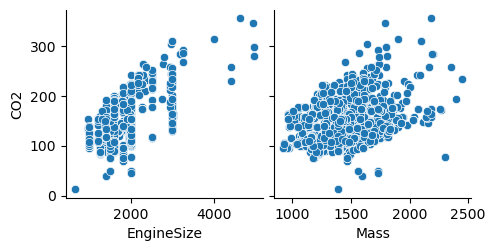

In [10]:
# plot all possible scatter diagrams
features = ['EngineSize', 'Mass']
sns.pairplot(cars_data_clean, x_vars=features, y_vars=['CO2']);

`EngineSize` and `Mass` are both displaying some association.

based on this, it seems like engine size will be better to model on because its got a stronger correlation. but we dont know that for sure

# Task 1: Building a model 

## Building a linear model using `EngineSize`
The code in the box below:
* Defines the `input_features`, i.e. the $x$ and the target, i.e. the $y$.
* Performs the training-testing split
* Creates the model: it finds the best values of $m$ and $c$ using the `LinearRegression().fit` command from the *sklearn* machine learning library and displays the values of $m$ and $c$.
* Creates a list of predictions and uses these to find the metrics $RMSE$ (root mean squared error) and $R^2$.

## Task
* Create models for CO2 for EngineSize, Mass and then both of these
* Use your models to make a prediction for CO2 emissions for:
<table> <tr> <th> Car </th> <th> Engine Size (cc) </th> <th> Mass (kg) </th> <th> Actual CO2 (g/km) </th></tr>
<tr>         <td> A   </td> <td> 1598 </td>             <td> 1970 </td>      <td> 190 </td></tr>
<tr>         <td> B   </td> <td> 999  </td>             <td> 1333 </td>      <td> 108 </td></tr>

* Compare your predictions to the actual CO2 emissions and decide which model is performing best



In [11]:
# Define the input and target data, perform the training-testing split
input_features = ['EngineSize']
X = cars_data_clean[input_features]
y = cars_data_clean['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(3))
print('Intercept: \n', linear_model.intercept_.round(3))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.038]
Intercept: 
 74.722
RMSE:  31.404
R²:  19.699 %


In [12]:
# Use this code block to calculate your predictions
0.038*1598+74.722

135.446

<a id='mass'></a>
## Building a linear model using `Mass`
> Copy and paste the model below to build a model using `Mass` as the input.

In [13]:
# Build and measure a model using Mass as the input feature.

# Define the input and target data, perform the training-testing split
input_features = ['Mass']
X = cars_data_clean[input_features]
y = cars_data_clean['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(3))
print('Intercept: \n', linear_model.intercept_.round(3))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")


Coefficients: 
 [0.036]
Intercept: 
 86.845
RMSE:  34.186
R²:  4.842 %


You should get a model of $y=0.036x+86.845$ with $RMSE=34.186$ and $R^2=4.842$%.

<a id='enmas'></a>
## Building a linear model using `EngineSize` and `Mass`
You can build a linear regression model that has multliple input features. To do this for engine size and mass you would use the code: 
`input_features=['EngineSize','Mass']`

In [14]:
# Build a model using EngineSize and mass
# Define the input and target data, perform the training-testing split
input_features = ['EngineSize','Mass']
X = cars_data_clean[input_features]
y = cars_data_clean['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(3))
print('Intercept: \n', linear_model.intercept_.round(3))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [ 0.044 -0.017]
Intercept: 
 88.055
RMSE:  31.223
R²:  20.623 %


- not that this isnt like a binary classification model where it picks the best of several input options; it uses everything you input
- there's no 'formula' per se to find the model. sklearn uses iteration to minimise difference between predictions from the model and actual values.
- there's a formula for this that you use at a-level, but that only works for 1 variable

You should get a model of $y=0.044e-0.017m+88.1$, where $e$ is the engine size and $m$ is the mass.

The model has $RMSE=31.223$ and $R^2=20.623$%.

## Interpreting $RMSE$ and $R^2$%.
The value of 20% for $R^2$% can be interpretted as showing that 20% of the variation in the values of $CO_2$ come from the model and 80% come from random variation, or *noise*.

The value of $31.223$ for $RMSE$ can be interpretted by comparing this to the distribution of $CO_2$ as it is a measure of the typical error in your predictions. Use the statistics and box plots below to answer the question: *Is this a good enough model?*

in a binary model, our best models are those with the highest precision and recall; there are other metrics we can judge models by, but these are the most intuitive

linear regression models use different metrics:
- RMSE (root mean squared error); a measure of how far away our predicted values (the points on the regression line) are from the true values. sort of like standard deviation 
- R^2 (coefficient of determination); basicaly how much variation in the y value can be attributed to changes in x; an R^2 value of 100% would tell us that changes in the y value are completely reliant on changes in the x value. this is the r value from PMCC squared (close to 1 = strong + correlation, close to -1 = strong - correlation)

going for *MIN* RMSE, **MAX** R^2

In [15]:
cars_data_clean['CO2'].describe()

count    3733.000000
mean      136.872489
std        36.005557
min        13.000000
25%       114.000000
50%       128.000000
75%       158.000000
max       356.000000
Name: CO2, dtype: float64

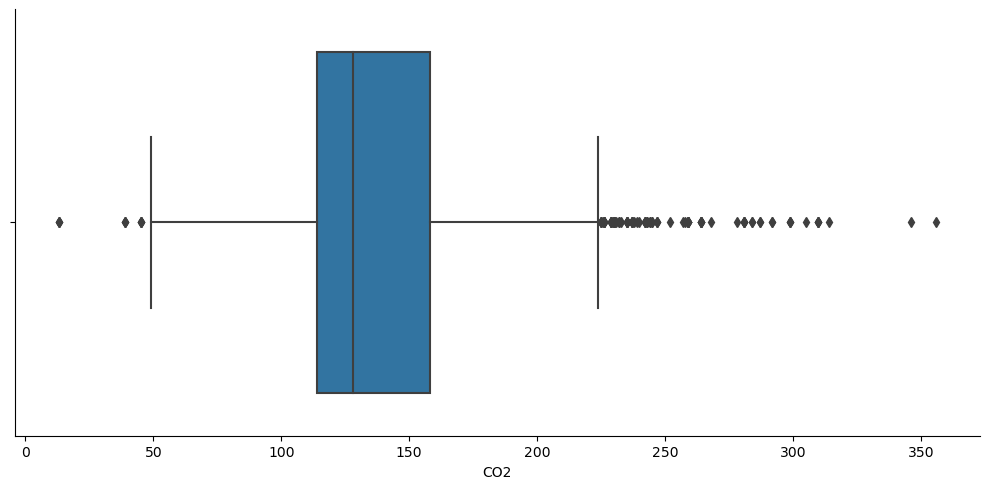

In [16]:
sns.catplot(data=cars_data_clean, kind='box', x='CO2', aspect=2);

# Creating models on slices

To **investigate categorical features** of the data, **slices** can be taken


In [17]:
# Slice for 2016 data, petrol cars

petrol_2016_data = cars_data_clean[(cars_data_clean['PropulsionType']=='Petrol')&(cars_data_clean['YearRegistered']==2016)].copy()

petrol_2016_data


,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
1,1465,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.797111,Petrol
2,3434,VOLKSWAGEN,1,14,South West,2,1395,2016,1316,113,0.242,0.033,NaN,0.048,0.348442,Petrol
3,1801,VAUXHALL,1,14,South West,4,1598,2016,1355,159,0.809,0.012,NaN,0.051,0.968447,Petrol
6,1323,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.526516,Petrol
7,1396,VAUXHALL,1,14,South West,5,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.691727,Petrol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3811,3379,VAUXHALL,1,14,North West,1,1398,2016,1163,118,0.463,0.010,NaN,0.031,0.700035,Petrol
3819,1903,VOLKSWAGEN,1,13,London,1,1197,2016,1139,109,0.199,0.018,NaN,0.035,0.078803,Petrol
3820,2913,FORD,1,5,North West,1,4951,2016,1799,299,0.621,0.018,NaN,0.046,0.787504,Petrol
3824,3498,FORD,1,14,South West,1,999,2016,1333,108,0.447,0.030,0.002,0.076,0.736612,Petrol


The code for the model can then be amended to use the slice as the data for X and y

In [18]:
# Define the input and target data, perform the training-testing split
input_features = ['Mass']
X = petrol_2016_data[input_features]
y = petrol_2016_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.1025]
Intercept: 
 -2.8103
RMSE:  14.028
R²:  60.642 %


## Task 2 - create models on slices of the data

* Use the 2016 petrol data to create other linear regression models to predict the CO2 emissions
* Try different slices on the categorical features and try to find the best model on these. You might like to try:
  - Diesel cars from 2016
  - Petrol cars from 2002

In [19]:
# Define the input and target data, perform the training-testing split
input_features = ['Mass',"EngineSize"]
X = petrol_2016_data[input_features]
y = petrol_2016_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.0506 0.0324]
Intercept: 
 16.9996
RMSE:  10.538
R²:  77.791 %


In [20]:
# Define the input and target data, perform the training-testing split
input_features = ["EngineSize"]
X = petrol_2016_data[input_features]
y = petrol_2016_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.0458]
Intercept: 
 62.3994
RMSE:  13.193
R²:  65.187 %


for 2016 registered cars,
mass < engine size < mass and engine size
in terms of the best regression model

In [21]:
london_data = cars_data_clean[(cars_data_clean["GovRegion"]=="London")].copy()

london_data

,ReferenceNumber,Make,PropulsionTypeId,BodyTypeId,GovRegion,KeeperTitleId,EngineSize,YearRegistered,Mass,CO2,CO,NOX,part,hc,Random number,PropulsionType
0,440,VAUXHALL,1,96,London,1,1598,2002,1970,190,0.219,0.026,NaN,0.037,0.430217,Petrol
8,264,TOYOTA,1,14,London,4,1998,2002,1440,212,0.760,0.040,NaN,0.080,0.279343,Petrol
10,1846,VAUXHALL,1,14,London,2,1398,2016,1199,137,0.645,0.008,NaN,0.044,0.778466,Petrol
17,371,VOLKSWAGEN,1,14,London,1,1390,2002,1220,180,0.096,0.064,NaN,0.092,0.080746,Petrol
19,1953,VAUXHALL,1,13,London,2,1398,2016,1141,118,0.463,0.010,NaN,0.031,0.880344,Petrol
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3804,543,VOLKSWAGEN,1,13,London,4,1390,2002,1143,154,0.252,0.040,NaN,0.065,0.909793,Petrol
3805,1567,BMW,2,2,London,2,1995,2016,1505,116,0.274,0.032,NaN,NaN,0.647936,Diesel
3813,2477,TOYOTA,8,96,London,5,1798,2016,1605,96,0.100,0.006,NaN,0.013,0.364537,Electric/Petrol
3819,1903,VOLKSWAGEN,1,13,London,1,1197,2016,1139,109,0.199,0.018,NaN,0.035,0.078803,Petrol


In [22]:
input_features = ["EngineSize","Mass"]
X = london_data[input_features]
y = london_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [ 0.0534 -0.0268]
Intercept: 
 95.6914
RMSE:  35.833
R²:  35.589 %


wow that's really bad!! seems like for london, enginesize and mass arent significant indicators as to CO2 emissions. maybe that's because there's more traffic, so people end up idling and releasing CO2 regardless? also a smaller data set than say, all 2016 registrations. could be playing a part

In [23]:
input_features = ["Mass"]
X = london_data[input_features]
y = london_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.0392]
Intercept: 
 91.1365
RMSE:  43.393
R²:  5.539 %


In [24]:
input_features = ["EngineSize"]
X = london_data[input_features]
y = london_data['CO2']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=1)

# create the model and display the parameters - output the coefficients and y-intercept
linear_model = LinearRegression().fit(X_train,y_train)
print('Coefficients: \n', linear_model.coef_.round(4))
print('Intercept: \n', linear_model.intercept_.round(4))

# create a list of the predictions and calculate the metrics (RMSE and R² score) by to the target values in y_test
y_pred = linear_model.predict(X_test) 
print('RMSE: ',mean_squared_error(y_test, y_pred, squared=False).round(3))
print('R²: ',(100*r2_score(y_test, y_pred)).round(3),"%")

Coefficients: 
 [0.0436]
Intercept: 
 73.8167
RMSE:  36.649
R²:  32.619 %
